# Dietary Patterns and Cardiovascular Health
**Denise Young | Python portfolio project | NHANES & USDA FPED 2017–2018**

A reproducible exploratory workflow linking public dietary, demographic, medication, laboratory, and examination data. The objective is to demonstrate data integration, validation, feature engineering, visualization, and cautious statistical interpretation—not to prove a dietary benefit.

## Questions
1. Is reported dietary fiber associated with measured total cholesterol?
2. Is a custom plant-food score associated with measured blood pressure?
3. How do estimates change with weighting and adjustment for age and reported treatment?

## Run this notebook
In Google Colab, run the setup cell, then **Runtime → Run all**. Internet is required on the first run. Downloads are cached in `data/raw`; tables and charts are written to `outputs`. Alternatively install `requirements.txt` and run `python analysis.py` locally. The original uploaded notebook is preserved separately; this is the packaged edition.

**Scope:** observational, cross-sectional exploration. The score is custom and unvalidated. Weighted regression coefficients are not a complete complex-survey analysis. No p-values or confidence intervals are presented.


In [1]:
# Install missing notebook dependencies (works in Colab and Jupyter).
import importlib.util
import subprocess
import sys
packages = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
            "statsmodels": "statsmodels", "py7zr": "py7zr"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


In [2]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
import io
import tempfile
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.formula.api as smf
import py7zr
from IPython.display import display

RAW = Path("data/raw")
OUT = Path("outputs")
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})
manifest = []

def download(url):
    """Cache source bytes and record provenance; reject HTML error pages."""
    path = RAW / url.rsplit("/", 1)[-1]
    if not path.exists():
        with urlopen(url, timeout=120) as response:
            payload = response.read()
        if b"<html" in payload[:1000].lower() or b"<!doctype html" in payload[:1000].lower():
            raise ValueError(f"Received an HTML page instead of data: {url}")
        path.write_bytes(payload)
    manifest.append({"file": path.name, "url": url,
                     "bytes": path.stat().st_size,
                     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
    return path

def load_xpt(url, **kwargs):
    return pd.read_sas(download(url), format="xport", **kwargs)

def save_chart(name):
    plt.savefig(OUT / name, bbox_inches="tight", dpi=160)


## 1. Dietary and laboratory data


In [3]:
# Load NHANES 2017–2018 dietary intake data
url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DR1TOT_J.xpt"

diet = load_xpt(url)

# Display the dataset size and selected columns
print(f"Rows: {diet.shape[0]:,}")
print(f"Columns: {diet.shape[1]:,}")

diet[["SEQN", "DR1TKCAL", "DR1TFIBE"]].head()

Rows: 8,704
Columns: 168


,SEQN,DR1TKCAL,DR1TFIBE
0,93703.0,NaN,NaN
1,93704.0,1230.0,5.9
2,93705.0,1202.0,8.4
3,93706.0,1987.0,7.1
4,93707.0,1775.0,10.9


In [4]:
# Load measured total blood cholesterol
cholesterol_url = (
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/"
    "DataFiles/TCHOL_J.xpt"
)

cholesterol = load_xpt(cholesterol_url)

# Match each participant's dietary and cholesterol records
# A left join keeps dietary records even when cholesterol is missing
combined = diet.merge(
    cholesterol[["SEQN", "LBXTC"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

print(f"Dietary records: {len(combined):,}")
print(f"Records with cholesterol results: {combined['LBXTC'].notna().sum():,}")

combined[["SEQN", "DR1TFIBE", "LBXTC"]].head()

Dietary records: 8,704
Records with cholesterol results: 6,738


,SEQN,DR1TFIBE,LBXTC
0,93703.0,NaN,NaN
1,93704.0,5.9,NaN
2,93705.0,8.4,157.0
3,93706.0,7.1,148.0
4,93707.0,10.9,189.0


## 2. Define the cholesterol sample


In [5]:
# Load participant demographics
demographics_url = (
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/"
    "DataFiles/DEMO_J.xpt"
)

demographics = load_xpt(demographics_url)

# Add age and survey-design fields
combined = combined.merge(
    demographics[["SEQN", "RIDAGEYR", "SDMVSTRA", "SDMVPSU"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Keep adults with reliable dietary recalls and both measurements
adults = combined.loc[
    (combined["RIDAGEYR"] >= 20)
    & (combined["DR1DRSTZ"] == 1)
    & (combined["WTDRD1"] > 0)
].dropna(subset=["DR1TFIBE", "LBXTC"]).copy()

print(f"Adults with usable dietary and cholesterol data: {len(adults):,}")

adults[["SEQN", "RIDAGEYR", "DR1TFIBE", "LBXTC"]].head()

Adults with usable dietary and cholesterol data: 4,489


,SEQN,RIDAGEYR,DR1TFIBE,LBXTC
2,93705.0,66.0,8.4,157.0
5,93708.0,66.0,16.6,209.0
8,93711.0,56.0,44.5,238.0
10,93713.0,67.0,14.6,184.0
11,93714.0,54.0,11.1,230.0


## 3. Validate and inspect distributions


In [6]:
# Give our main variables readable names
adults = adults.rename(columns={
    "RIDAGEYR": "age",
    "DR1TFIBE": "fiber_g",
    "LBXTC": "total_cholesterol_mg_dl"
})

# Summarize the data
display(
    adults[["age", "fiber_g", "total_cholesterol_mg_dl"]]
    .describe()
    .round(1)
)

# Check for duplicate participants and missing measurements
print("Duplicate participant IDs:", adults["SEQN"].duplicated().sum())

print("\nMissing values:")
print(
    adults[["age", "fiber_g", "total_cholesterol_mg_dl"]]
    .isna()
    .sum()
)

Duplicate participant IDs: 0

Missing values:
age                        0
fiber_g                    0
total_cholesterol_mg_dl    0
dtype: int64


,age,fiber_g,total_cholesterol_mg_dl
count,4489.0,4489.0,4489.0
mean,51.3,16.9,188.4
std,17.5,11.0,41.5
min,20.0,0.0,76.0
25%,36.0,9.2,160.0
50%,53.0,14.5,185.0
75%,65.0,21.9,213.0
max,80.0,103.4,446.0


## 4. Fiber and cholesterol: unadjusted exploration


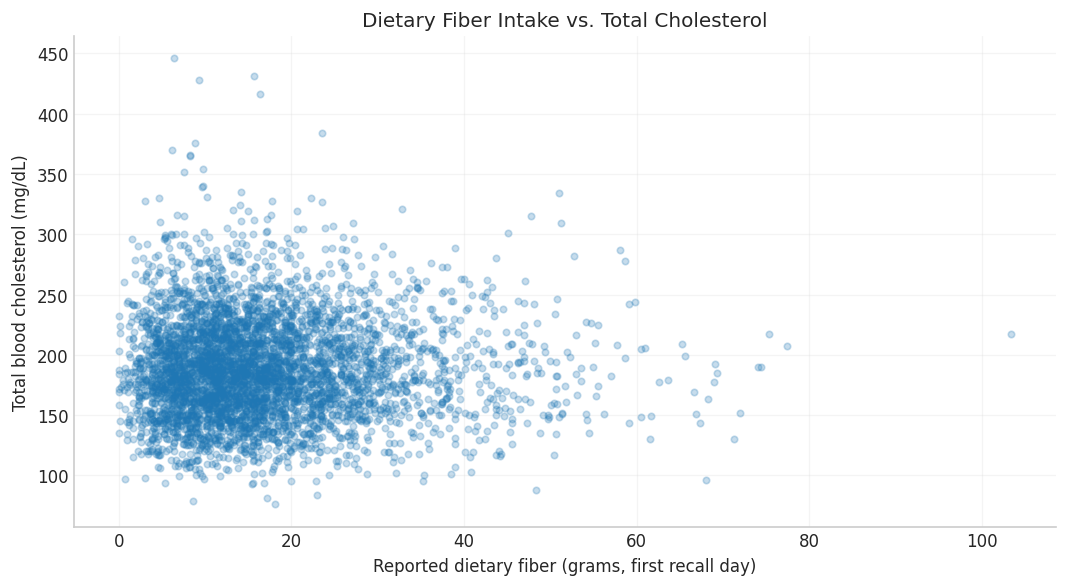

In [7]:
plt.figure(figsize=(9, 5))

plt.scatter(
    adults["fiber_g"],
    adults["total_cholesterol_mg_dl"],
    alpha=0.25,
    s=15
)

plt.xlabel("Reported dietary fiber (grams, first recall day)")
plt.ylabel("Total blood cholesterol (mg/dL)")
plt.title("Dietary Fiber Intake vs. Total Cholesterol")
plt.grid(alpha=0.2)
plt.tight_layout()
save_chart("fiber_cholesterol.png")
plt.show()

In [8]:
r = adults["fiber_g"].corr(adults["total_cholesterol_mg_dl"])

print(f"Pearson correlation: {r:.3f}")

Pearson correlation: -0.004


## 5. Summarize prescription records by participant
Medication data have multiple rows per participant. We identify seven statin ingredients, aggregate to person level, and retain unknown drug names separately. Other lipid-lowering drugs are not classified.

In [9]:
# Load prescription medication records
medication_url = (
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/"
    "DataFiles/RXQ_RX_J.xpt"
)

medications = load_xpt(medication_url, encoding="utf-8")

# Keep records for adults in our analysis
adult_medications = medications.loc[
    medications["SEQN"].isin(adults["SEQN"])
].copy()

display(
    adult_medications[["SEQN", "RXDUSE", "RXDDRUG"]].head(10)
)

print("Medication records:", len(adult_medications))
print("Unique participants:", adult_medications["SEQN"].nunique())

Medication records: 12555
Unique participants: 4489


,SEQN,RXDUSE,RXDDRUG
2,93705.0,1.0,ENALAPRIL; HYDROCHLOROTHIAZIDE
3,93705.0,1.0,MELOXICAM
4,93705.0,1.0,OMEPRAZOLE
7,93708.0,1.0,AMLODIPINE
8,93708.0,1.0,LOSARTAN
9,93708.0,1.0,SIMVASTATIN
15,93711.0,2.0,
17,93713.0,1.0,ACETAMINOPHEN; OXYCODONE
18,93714.0,1.0,INSULIN ISOPHANE; INSULIN REGULAR
19,93715.0,1.0,ACETAMINOPHEN; OXYCODONE


In [10]:
# Generic statin names to look for
statin_names = [
    "atorvastatin",
    "rosuvastatin",
    "simvastatin",
    "pravastatin",
    "lovastatin",
    "fluvastatin",
    "pitavastatin"
]

# Match names regardless of capitalization
pattern = "|".join(statin_names)

adult_medications["statin_record"] = (
    adult_medications["RXDDRUG"]
    .str.contains(pattern, case=False, na=False)
)

# Inspect the medication names that matched
display(
    adult_medications.loc[
        adult_medications["statin_record"], "RXDDRUG"
    ]
    .value_counts()
    .rename_axis("Medication")
    .reset_index(name="Records")
)

# Count each participant once
statin_users = adult_medications.loc[
    adult_medications["statin_record"], "SEQN"
].nunique()

print("Participants reporting a statin:", statin_users)

Participants reporting a statin: 999


,Medication,Records
0,ATORVASTATIN,486
1,SIMVASTATIN,255
2,PRAVASTATIN,120
3,ROSUVASTATIN,82
4,LOVASTATIN,48
5,EZETIMIBE; SIMVASTATIN,6
6,PITAVASTATIN,5
7,FLUVASTATIN,2


In [11]:
# Identify incomplete or unknown medication information
drug_names = (
    adult_medications["RXDDRUG"]
    .fillna("")
    .str.strip()
    .str.upper()
)

adult_medications["uncertain_record"] = (
    ~adult_medications["RXDUSE"].isin([1, 2])
    | (
        adult_medications["RXDUSE"].eq(1)
        & drug_names.isin(["", "55555", "77777", "99999"])
    )
)

# Summarize multiple medication records to one row per person
med_summary = adult_medications.groupby("SEQN").agg(
    reported_statin=("statin_record", "any"),
    uncertain_medication=("uncertain_record", "any")
)

med_summary["statin_status"] = "No statin reported"
med_summary.loc[
    med_summary["uncertain_medication"], "statin_status"
] = "Unknown"

# A known statin takes priority over other unknown medications
med_summary.loc[
    med_summary["reported_statin"], "statin_status"
] = "Statin reported"

# Join without multiplying participant rows
analysis = adults.merge(
    med_summary[["statin_status"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

analysis["statin_status"] = analysis["statin_status"].fillna("Unknown")

# Calculate a separate correlation for each group
results = []

for status, group in analysis.groupby("statin_status"):
    results.append({
        "Statin status": status,
        "Participants": len(group),
        "Pearson r": group["fiber_g"].corr(
            group["total_cholesterol_mg_dl"]
        )
    })

display(pd.DataFrame(results).round(3))
statin_results = pd.DataFrame(results)
statin_results.to_csv(OUT / "cholesterol_by_statin.csv", index=False)


,Statin status,Participants,Pearson r
0,No statin reported,3423,-0.005
1,Statin reported,999,-0.027
2,Unknown,67,-0.052


## 6. Sensitivity check: two dietary recall days
Restrict to two reliable recalls with positive two-day weights. Compare Day 1 and two-day means in the same people; these Pearson correlations remain unweighted.

In [12]:
# Load the second dietary recall
day2_url = (
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/"
    "DataFiles/DR2TOT_J.xpt"
)

diet_day2 = load_xpt(day2_url)

# Add Day 2 fields to our existing analysis
two_day = analysis.merge(
    diet_day2[["SEQN", "DR2TFIBE", "DR2DRSTZ"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Day 1 reliability was already checked.
# Now require reliable Day 2 data and a positive two-day weight.
two_day = two_day.loc[
    (two_day["DR2DRSTZ"] == 1)
    & (two_day["WTDR2D"] > 0)
].dropna(subset=["DR2TFIBE"]).copy()

two_day["average_fiber_g"] = (
    two_day["fiber_g"] + two_day["DR2TFIBE"]
) / 2

print(f"Adults with two usable recalls: {len(two_day):,}")

# Compare Day 1 and the two-day average in the SAME participants
print(
    "Day 1 correlation:",
    round(two_day["fiber_g"].corr(
        two_day["total_cholesterol_mg_dl"]
    ), 3)
)

print(
    "Two-day average correlation:",
    round(two_day["average_fiber_g"].corr(
        two_day["total_cholesterol_mg_dl"]
    ), 3)
)

Adults with two usable recalls: 3,927
Day 1 correlation: -0.001
Two-day average correlation: -0.02


## 7. Blood-pressure data and a separate sample
Adults need not have cholesterol measurements to enter the BP analysis. For this exploration we average available readings 1–3, retaining recorded zero diastolic values. We do not use fourth attempts. This is a project-specific averaging choice, not a clinical diagnosis.

In [13]:
# Load NHANES 2017–2018 blood-pressure measurements
bp_url = (
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/"
    "DataFiles/BPX_J.xpt"
)

blood_pressure = load_xpt(bp_url)

# Inspect the first three systolic and diastolic readings
bp_columns = [
    "SEQN",
    "BPXSY1", "BPXSY2", "BPXSY3",
    "BPXDI1", "BPXDI2", "BPXDI3"
]

display(blood_pressure[bp_columns].head())

print("Participants in blood-pressure file:",
      blood_pressure["SEQN"].nunique())

Participants in blood-pressure file: 8704


,SEQN,BPXSY1,BPXSY2,BPXSY3,BPXDI1,BPXDI2,BPXDI3
0,93703.0,NaN,NaN,NaN,NaN,NaN,NaN
1,93704.0,NaN,NaN,NaN,NaN,NaN,NaN
2,93705.0,NaN,NaN,202.0,NaN,NaN,62.0
3,93706.0,112.0,114.0,108.0,74.0,70.0,76.0
4,93707.0,128.0,128.0,128.0,38.0,46.0,58.0


In [14]:
# Start with demographics and Day 1 dietary data
bp_analysis = demographics[
    ["SEQN", "RIDAGEYR", "SDMVSTRA", "SDMVPSU"]
].merge(
    diet[["SEQN", "DR1DRSTZ", "WTDRD1"]],
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

# Add the blood-pressure readings
bp_analysis = bp_analysis.merge(
    blood_pressure[bp_columns],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Keep adults with reliable Day 1 dietary recalls
bp_analysis = bp_analysis.loc[
    (bp_analysis["RIDAGEYR"] >= 20)
    & (bp_analysis["DR1DRSTZ"] == 1)
    & (bp_analysis["WTDRD1"] > 0)
].copy()

# For this exploratory analysis, average available readings 1–3
systolic_cols = ["BPXSY1", "BPXSY2", "BPXSY3"]
diastolic_cols = ["BPXDI1", "BPXDI2", "BPXDI3"]

bp_analysis["systolic_mean"] = (
    bp_analysis[systolic_cols].mean(axis=1)
)
bp_analysis["diastolic_mean"] = (
    bp_analysis[diastolic_cols].mean(axis=1)
)

# Retain participants with both blood-pressure measures
bp_analysis = bp_analysis.dropna(
    subset=["systolic_mean", "diastolic_mean"]
).copy()

print(f"Adults in the initial BP sample: {len(bp_analysis):,}")

display(
    bp_analysis[
        ["SEQN", "RIDAGEYR", "systolic_mean", "diastolic_mean"]
    ].head().round(1)
)

Adults in the initial BP sample: 4,591


,SEQN,RIDAGEYR,systolic_mean,diastolic_mean
2,93705.0,66.0,202.0,62.0
5,93708.0,66.0,141.0,77.0
8,93711.0,56.0,101.3,66.7
10,93713.0,67.0,104.7,72.0
11,93714.0,54.0,164.0,94.0


## 8. Download and read USDA food-group data
USDA distributes a self-extracting 7-Zip archive. Read its embedded 7z payload with `py7zr`; **never execute the Windows program**. Extraction occurs in a temporary directory, and only the SAS dataset is read.

In [15]:
fped_url = "https://www.ars.usda.gov/ARSUserFiles/80400530/apps/FPED_DR1TOT_1718_sas.exe"
archive_payload = download(fped_url).read_bytes()
signature = b"7z\xbc\xaf\x27\x1c"
offset = archive_payload.find(signature)
if offset < 0:
    raise ValueError("Expected embedded 7-Zip archive not found; check the USDA download.")
with tempfile.TemporaryDirectory() as temporary:
    with py7zr.SevenZipFile(io.BytesIO(archive_payload[offset:]), mode="r") as archive:
        names = [name for name in archive.getnames()
                 if name.lower().endswith(".sas7bdat")]
        if len(names) != 1:
            raise ValueError(f"Expected one SAS dataset; found {names}")
        name = names[0]
        if Path(name).is_absolute() or ".." in Path(name).parts:
            raise ValueError("Unsafe archive member path")
        archive.extract(path=temporary, targets=[name])
    plant_foods = pd.read_sas(Path(temporary) / name,
                              format="sas7bdat", encoding="latin-1")
print(f"USDA participant records: {len(plant_foods):,}")
assert plant_foods["SEQN"].is_unique


USDA participant records: 8,704


## 9. Link USDA food groups


In [16]:
# Select food-group measures for our analysis
food_columns = [
    "SEQN",
    "DR1T_F_TOTAL",
    "DR1T_F_JUICE",
    "DR1T_V_TOTAL",
    "DR1T_V_LEGUMES",
    "DR1T_G_WHOLE",
    "DR1T_G_REFINED",
    "DR1T_PF_SOY",
    "DR1T_PF_NUTSDS",
    "DR1T_PF_LEGUMES",
    "DR1T_PF_MPS_TOTAL",
    "DR1T_PF_EGGS",
    "DR1T_D_TOTAL",
    "DR1T_ADD_SUGARS"
]

# Join food-group intake to blood-pressure records
plant_bp = bp_analysis.merge(
    plant_foods[food_columns],
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

print(f"Adults with matched food-group records: {len(plant_bp):,}")

display(
    plant_bp[
        ["DR1T_F_TOTAL", "DR1T_V_TOTAL",
         "DR1T_G_WHOLE", "DR1T_PF_MPS_TOTAL",
         "DR1T_D_TOTAL"]
    ].describe().round(2)
)

Adults with matched food-group records: 4,591


,DR1T_F_TOTAL,DR1T_V_TOTAL,DR1T_G_WHOLE,DR1T_PF_MPS_TOTAL,DR1T_D_TOTAL
count,4591.00,4591.00,4591.00,4591.00,4591.00
mean,0.94,1.49,0.82,4.82,1.30
std,1.44,1.31,1.41,4.37,1.37
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.54,0.00,1.92,0.31
50%,0.35,1.17,0.00,3.95,0.96
75%,1.39,2.09,1.21,6.59,1.87
max,19.08,12.14,15.68,87.54,15.03


## 10. Engineer a custom plant-food score
Six components increase the score: whole fruit, vegetables excluding legumes, whole grains, legumes, soy, nuts/seeds. Three decrease it: meat/poultry/seafood, eggs, dairy. Each is expressed per 1,000 kcal, ranked within the eligible BP sample with average ties, and equally weighted. The mean percentile rank × 100 is a relative score, not percent plant calories. Legumes enter once. Refined grains, added sugar, oils, and solid fats are omitted, so this is not an overall diet-quality index. Ranks are unweighted and sample-dependent.

In [17]:
# Add calorie intake
scored_bp = plant_bp.merge(
    diet[["SEQN", "DR1TKCAL"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Whole fruit excludes fruit juice
scored_bp["whole_fruit"] = (
    scored_bp["DR1T_F_TOTAL"] - scored_bp["DR1T_F_JUICE"]
)

positive_groups = [
    "whole_fruit", "DR1T_V_TOTAL", "DR1T_G_WHOLE",
    "DR1T_PF_LEGUMES", "DR1T_PF_SOY", "DR1T_PF_NUTSDS"
]

negative_groups = [
    "DR1T_PF_MPS_TOTAL", "DR1T_PF_EGGS", "DR1T_D_TOTAL"
]

groups = positive_groups + negative_groups

# Require complete food-group data and positive calories
scored_bp = scored_bp.dropna(
    subset=groups + ["DR1TKCAL"]
).copy()

scored_bp = scored_bp.loc[
    scored_bp["DR1TKCAL"] > 0
].copy()

# Express each food group per 1,000 calories
density = scored_bp[groups].div(
    scored_bp["DR1TKCAL"], axis=0
) * 1000

# Rank each component; reverse ranks for animal-food groups
components = density.rank(pct=True, method="average")

components[negative_groups] = (
    (-density[negative_groups])
    .rank(pct=True, method="average")
)

# Equal weight for each of the nine components
scored_bp["plant_score"] = components.mean(axis=1) * 100

print(f"Adults with scores: {len(scored_bp):,}")

display(
    scored_bp[
        ["plant_score", "systolic_mean", "diastolic_mean"]
    ].describe().round(1)
)
assert density.ge(-1e-8).all().all(), "Negative food density needs investigation"
assert scored_bp["SEQN"].is_unique


Adults with scores: 4,591


,plant_score,systolic_mean,diastolic_mean
count,4591.0,4591.0,4591.0
mean,50.0,127.0,72.7
std,9.7,19.8,12.8
min,23.5,80.0,0.0
25%,43.2,112.7,65.3
50%,49.4,124.0,72.7
75%,55.9,137.3,80.0
max,88.6,238.0,125.0


## 11. Unadjusted score–blood-pressure associations


systolic_mean: Pearson r = -0.006
diastolic_mean: Pearson r = -0.050


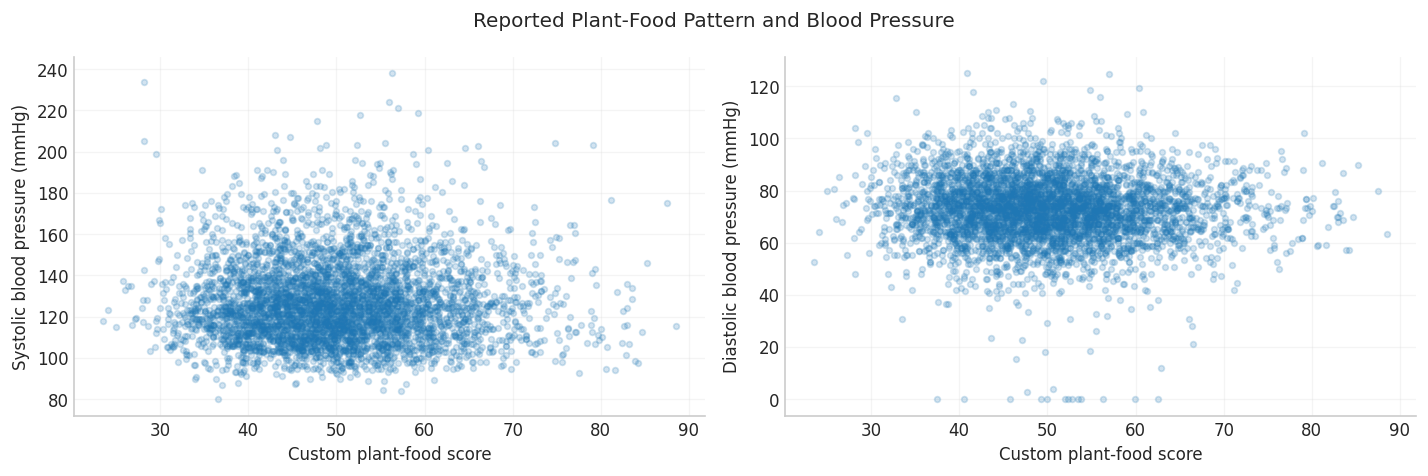

In [18]:
# Calculate unweighted correlations
for outcome in ["systolic_mean", "diastolic_mean"]:
    r = scored_bp["plant_score"].corr(scored_bp[outcome])
    print(f"{outcome}: Pearson r = {r:.3f}")

# Plot both comparisons
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, outcome, label in zip(
    axes,
    ["systolic_mean", "diastolic_mean"],
    ["Systolic blood pressure (mmHg)",
     "Diastolic blood pressure (mmHg)"]
):
    ax.scatter(
        scored_bp["plant_score"],
        scored_bp[outcome],
        alpha=0.2,
        s=12
    )
    ax.set_xlabel("Custom plant-food score")
    ax.set_ylabel(label)
    ax.grid(alpha=0.2)

fig.suptitle("Reported Plant-Food Pattern and Blood Pressure")
plt.tight_layout()
save_chart("plant_score_blood_pressure.png")
plt.show()

## 12. Preserve questionnaire skip patterns
BPQ050A directly reports current treatment for hypertension. Skips inferred from BPQ020 or BPQ040A are labeled separately; they do not prove absence of all BP-lowering drugs.

In [19]:
# Load blood-pressure questionnaire responses
bpq_url = (
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/"
    "DataFiles/BPQ_J.xpt"
)

bp_questions = load_xpt(bpq_url)

bp_ready = scored_bp.merge(
    bp_questions[["SEQN", "BPQ020", "BPQ040A", "BPQ050A"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Start with unknown status
bp_ready["bp_med_status"] = "Unknown"

# Explicitly reported not currently taking medication
bp_ready.loc[
    bp_ready["BPQ050A"].eq(2),
    "bp_med_status"
] = "Reported no current BP medicine"

# Medication question skipped based on earlier responses
bp_ready.loc[
    bp_ready["BPQ050A"].isna()
    & (
        bp_ready["BPQ020"].eq(2)
        | bp_ready["BPQ040A"].eq(2)
    ),
    "bp_med_status"
] = "No BP treatment reported (question skipped)"

# Explicitly reported current medication use
bp_ready.loc[
    bp_ready["BPQ050A"].eq(1),
    "bp_med_status"
] = "Reported current BP medicine"

display(
    bp_ready["bp_med_status"]
    .value_counts()
    .rename_axis("Medication status")
    .reset_index(name="Participants")
)

,Medication status,Participants
0,No BP treatment reported (question skipped),2980
1,Reported current BP medicine,1365
2,Reported no current BP medicine,233
3,Unknown,13


## 13. Associations by reported treatment


In [20]:
results = []

for status, group in bp_ready.groupby("bp_med_status"):
    results.append({
        "Medication status": status,
        "Participants": len(group),
        "Average age": group["RIDAGEYR"].mean(),
        "Systolic r": group["plant_score"].corr(
            group["systolic_mean"]
        ),
        "Diastolic r": group["plant_score"].corr(
            group["diastolic_mean"]
        )
    })

group_results = pd.DataFrame(results)

display(group_results.round(3))
group_results.to_csv(OUT / "blood_pressure_by_treatment.csv", index=False)


,Medication status,Participants,Average age,Systolic r,Diastolic r
0,No BP treatment reported (question skipped),2980,45.476,-0.019,-0.032
1,Reported current BP medicine,1365,63.682,-0.021,-0.093
2,Reported no current BP medicine,233,51.944,0.101,0.035
3,Unknown,13,57.923,0.103,0.136


## 14. Weighted regression coefficients
Use WTDRD1 for the one-day dietary score. WLS adjusts for centered age, age squared, and three reported treatment categories; 13 unknown responses are excluded. No survey-design-aware standard errors are calculated. This model is exploratory, not fully adjusted for confounding.

In [21]:
import statsmodels.formula.api as smf

# Exclude unknown medication status
model_data = bp_ready.loc[
    bp_ready["bp_med_status"] != "Unknown"
].copy()

# Scale the score so its coefficient describes a 10-point increase
model_data["plant_score_10"] = model_data["plant_score"] / 10

# Center age and allow a curved relationship with blood pressure
model_data["age_centered"] = model_data["RIDAGEYR"] - 50

results = []

for outcome in ["systolic_mean", "diastolic_mean"]:
    model = smf.wls(
        formula=(
            f"{outcome} ~ plant_score_10"
            " + age_centered + I(age_centered ** 2)"
            " + C(bp_med_status)"
        ),
        data=model_data,
        weights=model_data["WTDRD1"],
        missing="raise"
    ).fit()

    results.append({
        "Outcome": outcome,
        "Participants": int(model.nobs),
        "BP difference per 10 score points (mmHg)":
            model.params["plant_score_10"]
    })

display(pd.DataFrame(results).round(3))
weighted_adjusted_results = pd.DataFrame(results)
weighted_adjusted_results.to_csv(OUT / "weighted_adjusted_coefficients.csv", index=False)


,Outcome,Participants,BP difference per 10 score points (mmHg)
0,systolic_mean,4578,-1.266
1,diastolic_mean,4578,-0.800


## 15. Separate weighting from adjustment
Compare four specifications on exactly the same complete-case participants and the same fixed dietary score. The sequence documents how estimates change; it is not a search for statistical significance. Coefficients are in mmHg per 10 score points. No confidence intervals or p-values are reported.

,outcome,model,n,mmHg_per_10_points
0,systolic_mean,"Unweighted, unadjusted",4578,-0.131
1,systolic_mean,"Weighted, unadjusted",4578,-0.572
2,systolic_mean,"Unweighted, age/treatment adjusted",4578,-1.135
3,systolic_mean,"Weighted, age/treatment adjusted",4578,-1.266
4,diastolic_mean,"Unweighted, unadjusted",4578,-0.665
5,diastolic_mean,"Weighted, unadjusted",4578,-0.817
6,diastolic_mean,"Unweighted, age/treatment adjusted",4578,-0.732
7,diastolic_mean,"Weighted, age/treatment adjusted",4578,-0.800


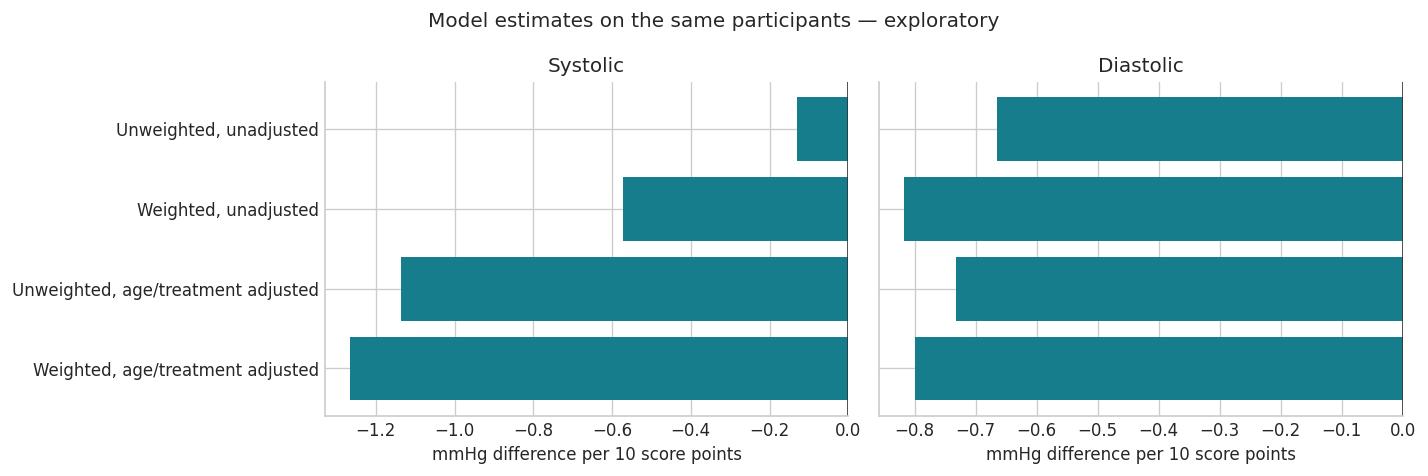

In [22]:
comparison = []
for outcome in ["systolic_mean", "diastolic_mean"]:
    for weighted, adjusted, label in [
        (False, False, "Unweighted, unadjusted"),
        (True, False, "Weighted, unadjusted"),
        (False, True, "Unweighted, age/treatment adjusted"),
        (True, True, "Weighted, age/treatment adjusted")
    ]:
        formula = f"{outcome} ~ plant_score_10"
        if adjusted:
            formula += " + age_centered + I(age_centered ** 2) + C(bp_med_status)"
        if weighted:
            fitted = smf.wls(formula, model_data,
                             weights=model_data["WTDRD1"], missing="raise").fit()
        else:
            fitted = smf.ols(formula, model_data, missing="raise").fit()
        comparison.append({"outcome": outcome, "model": label,
                           "n": int(fitted.nobs),
                           "mmHg_per_10_points": fitted.params["plant_score_10"]})
model_comparison = pd.DataFrame(comparison)
model_comparison.to_csv(OUT / "model_comparison.csv", index=False)
display(model_comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, outcome, title in zip(axes, ["systolic_mean", "diastolic_mean"],
                               ["Systolic", "Diastolic"]):
    rows = model_comparison.loc[model_comparison["outcome"].eq(outcome)]
    ax.barh(rows["model"], rows["mmHg_per_10_points"], color="#167d8d")
    ax.axvline(0, color="#333333", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("mmHg difference per 10 score points")
axes[0].invert_yaxis()
fig.suptitle("Model estimates on the same participants — exploratory")
plt.tight_layout()
save_chart("model_comparison.png")
plt.show()


## 16. Export validation and reproducibility records
Only aggregate tables and figures are packaged for GitHub. Raw source files and participant-level data stay out of the repository. Download hashes identify the bytes used; software versions identify the execution environment.

In [23]:
cohort_counts = pd.DataFrame([
    {"sample": "Cholesterol, Day 1", "n": len(adults)},
    {"sample": "Cholesterol, two recalls", "n": len(two_day)},
    {"sample": "Blood pressure with dietary score", "n": len(scored_bp)},
    {"sample": "Blood pressure regression, known treatment status", "n": len(model_data)}
])
cohort_counts.to_csv(OUT / "cohort_counts.csv", index=False)
checks = {
    "cholesterol_ids_unique": bool(adults["SEQN"].is_unique),
    "bp_ids_unique": bool(bp_ready["SEQN"].is_unique),
    "positive_model_weights": bool(model_data["WTDRD1"].gt(0).all()),
    "complete_model_variables": bool(model_data[
        ["plant_score_10", "age_centered", "systolic_mean", "diastolic_mean", "WTDRD1"]
    ].notna().all().all()),
    "treatment_counts_reconcile": bool(bp_ready["bp_med_status"].value_counts().sum() == len(bp_ready))
}
assert all(checks.values()), checks
(OUT / "validation.json").write_text(json.dumps(checks, indent=2))
(OUT / "source_manifest.json").write_text(json.dumps(manifest, indent=2))
versions = {"python": platform.python_version(), "pandas": pd.__version__,
            "numpy": np.__version__, "matplotlib": __import__("matplotlib").__version__,
            "statsmodels": statsmodels.__version__, "py7zr": py7zr.__version__}
(OUT / "software_versions.json").write_text(json.dumps(versions, indent=2))
display(cohort_counts)
print("Validation passed. Aggregate tables and charts saved in:", OUT.resolve())


Validation passed. Aggregate tables and charts saved in: /workspace/scratch/1f757ed17f72/public_health_python/outputs


,sample,n
0,"Cholesterol, Day 1",4489
1,"Cholesterol, two recalls",3927
2,Blood pressure with dietary score,4591
3,"Blood pressure regression, known treatment status",4578


## Interpretation and limitations
- Raw correlations show little linear association. Report near-null findings alongside adjusted estimates.
- WLS coefficients describe associations under a chosen model; weighting and adjustment can change the comparison. They do not establish causality.
- This custom score is not a validated PDI/hPDI or a vegan classification. It is equally weighted, uses unweighted within-sample ranks, and is based on one recall day. Different definitions may change results.
- Blood pressure is averaged from available readings 1–3; fourth attempts are not incorporated. Recorded zero diastolic values are retained. Alternative averaging rules warrant sensitivity analysis.
- Age and questionnaire-reported treatment do not remove all confounding. Sex, socioeconomic factors, sodium, physical activity, smoking, alcohol, and other factors remain unaddressed. Medication adjustment may itself complicate causal interpretation.
- Two recall days do not establish usual intake; diet may have changed after a diagnosis. Prescription data identify statins only, not all lipid-lowering drugs.
- Dietary weights are used for WLS coefficients, but strata, PSUs, and domain-analysis variance estimation are not implemented. Do not use default WLS uncertainty estimates as complex-survey estimates or claim nationally representative effects.
- Complete-case selection, nonresponse, top-coded age, and sampling variability limit interpretation. No clinical recommendations are made.

## Data documentation
- [CDC NHANES 2017–2018](https://wwwn.cdc.gov/nchs/nhanes/search/DataPage.aspx?Cycle=2017-2018)
- [Day 1 dietary recall](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DR1TOT_J.htm)
- [Day 2 dietary recall](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DR2TOT_J.htm)
- [Blood-pressure measurements](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPX_J.htm)
- [BP questionnaire and skip patterns](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPQ_J.htm)
- [USDA FPED datasets](https://www.ars.usda.gov/northeast-area/beltsville-md-bhnrc/beltsville-human-nutrition-research-center/food-surveys-research-group/docs/fped-databases/)
- [USDA FPED 2017–2018 methodology](https://www.ars.usda.gov/ARSUserFiles/80400530/pdf/fped/FPED_1718.pdf)

Prepared with AI assistance. The analyst should review the code and limitations before presenting the project in interviews.
